<a href="https://colab.research.google.com/github/febrynia13-oss/P03_24512220002_FebryTaniaZahra.ipynb/blob/main/P03_24512220002_FebryTaniaZahra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pertemuan 3 — Formulasi Masalah dan Ruang Keadaan
**PIF403 Pengantar Kecerdasan Buatan · Prodi Informatika Universitas Adzkia**

Pada pertemuan 2 kita merancang agen dengan PEAS. Sekarang kita menjawab pertanyaan berikutnya: *bagaimana sebuah agen menemukan urutan tindakan untuk mencapai tujuannya?* Langkah pertama bukan menulis algoritma, melainkan **memformulasikan masalah**.

**Setelah menyelesaikan notebook ini Anda mampu:**
1. menuliskan lima komponen formulasi masalah (status awal, aksi, model transisi, uji tujuan, biaya jalur) dalam kode;
2. memodelkan masalah rute dan puzzle sebagai **graf ruang keadaan** dengan NetworkX;
3. menghitung dan menalar ukuran ruang keadaan.

**Cara pakai:** pilih *File → Save a copy in Drive*, isi identitas, lalu jalankan sel dari atas ke bawah. Bagian bertanda **Latihan** dikerjakan sendiri dan menjadi bagian dari penilaian A1.

In [1]:
# Isi identitas Anda sebelum mulai
NAMA = "Febry Tania Zahra"
NIM = "24512220002"
print(f"Notebook P3 dikerjakan oleh: {NAMA} ({NIM})")

Notebook P3 dikerjakan oleh: Febry Tania Zahra (24512220002)


## 1. Menyiapkan data peta

Kasus berjalan kita: **agen perencana rute di Sumatera Barat**. Datanya ada di dua berkas yang dibagikan dosen lewat LMS:

| Berkas | Isi |
|---|---|
| `peta_sumbar.csv` | daftar ruas jalan: kota asal, kota tujuan, jarak (km) |
| `kota_sumbar.csv` | daftar kota beserta koordinat untuk menggambar |

Jalankan sel di bawah lalu **unggah kedua berkas tersebut**. Jarak pada data ini adalah angka perkiraan untuk keperluan latihan, bukan data resmi.

In [2]:
import os

BERKAS = ["peta_sumbar.csv", "kota_sumbar.csv"]
if not all(os.path.exists(b) for b in BERKAS):
    from google.colab import files
    print("Unggah berkas:", ", ".join(BERKAS))
    files.upload()

for b in BERKAS:
    assert os.path.exists(b), f"Berkas {b} belum diunggah. Jalankan ulang sel ini."
print("Semua berkas tersedia.")

Unggah berkas: peta_sumbar.csv, kota_sumbar.csv


Saving peta_sumbar.csv to peta_sumbar.csv
Saving kota_sumbar.csv to kota_sumbar.csv
Semua berkas tersedia.


In [3]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

jalan = pd.read_csv("peta_sumbar.csv")
kota = pd.read_csv("kota_sumbar.csv")
print("Jumlah kota:", len(kota), "| jumlah ruas jalan:", len(jalan))
jalan.head()

Jumlah kota: 12 | jumlah ruas jalan: 18


,kota_asal,kota_tujuan,jarak_km
0,Padang,Pariaman,56
1,Padang,Padang Panjang,72
2,Padang,Solok,64
3,Padang,Painan,77
4,Pariaman,Lubuk Basung,52


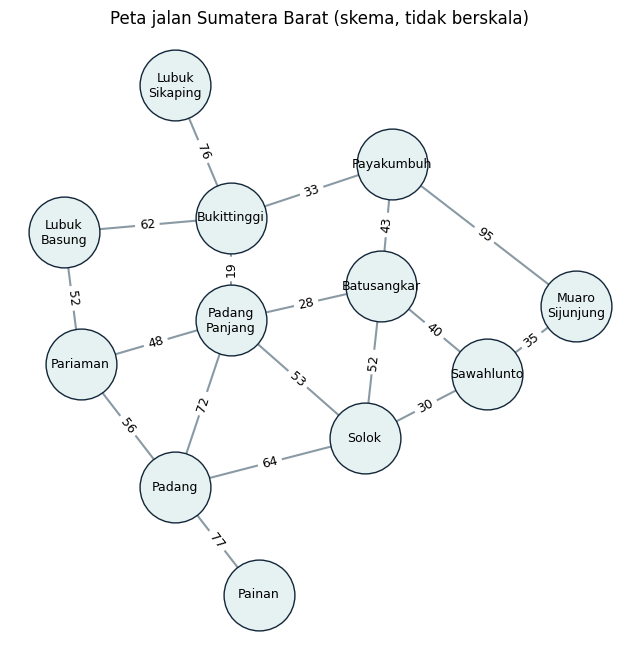

In [4]:
# Bangun graf tak berarah: simpul = kota, sisi = ruas jalan, bobot = jarak
G = nx.Graph()
for _, r in jalan.iterrows():
    G.add_edge(r.kota_asal, r.kota_tujuan, jarak=int(r.jarak_km))

POSISI = {r.kota: (r.x_gambar, r.y_gambar) for _, r in kota.iterrows()}

def gambar_peta(G, jalur=None, judul="Peta jalan Sumatera Barat (skema, tidak berskala)"):
    plt.figure(figsize=(8, 8))
    nx.draw_networkx_nodes(G, POSISI, node_size=2600, node_color="#E6F2F1", edgecolors="#12263A")
    nx.draw_networkx_labels(G, POSISI, labels={k: k.replace(" ", "\n") for k in G}, font_size=9)
    nx.draw_networkx_edges(G, POSISI, edge_color="#8A9AA5", width=1.5)
    nx.draw_networkx_edge_labels(G, POSISI, edge_labels=nx.get_edge_attributes(G, "jarak"), font_size=9)
    if jalur:
        sisi = list(zip(jalur, jalur[1:]))
        nx.draw_networkx_edges(G, POSISI, edgelist=sisi, edge_color="#D1495B", width=4)
    plt.title(judul); plt.axis("off"); plt.show()

gambar_peta(G)

## 2. Lima komponen formulasi masalah

Sebuah **masalah pencarian** didefinisikan oleh lima komponen:

| Komponen | Pertanyaan yang dijawab | Contoh pada masalah rute |
|---|---|---|
| **Status awal** | Agen mulai dari mana? | `Padang` |
| **Aksi** `aksi(s)` | Apa saja yang bisa dilakukan pada status `s`? | pergi ke kota tetangga |
| **Model transisi** `hasil(s, a)` | Status apa yang dihasilkan aksi `a` pada `s`? | berada di kota tetangga itu |
| **Uji tujuan** `tujuan(s)` | Apakah `s` sudah merupakan tujuan? | `s == "Payakumbuh"` |
| **Biaya jalur** `biaya(s, a, s2)` | Berapa ongkos satu langkah? | jarak ruas jalan (km) |

Kita tuangkan menjadi kelas induk `Masalah`. Semua masalah berikutnya (rute, ember air, 8-puzzle) tinggal mewarisi kelas ini. Keuntungannya besar: minggu depan algoritma pencarian cukup ditulis **sekali** dan langsung bekerja untuk semua masalah.

In [5]:
class Masalah:
    """Kerangka umum masalah pencarian. Kelas turunan mengisi kelima komponen."""
    def __init__(self, awal):
        self.awal = awal                      # 1. status awal
    def aksi(self, s):                        # 2. aksi yang tersedia pada status s
        raise NotImplementedError
    def hasil(self, s, a):                    # 3. model transisi
        raise NotImplementedError
    def tujuan(self, s):                      # 4. uji tujuan
        raise NotImplementedError
    def biaya(self, s, a, s2):                # 5. biaya satu langkah (default 1)
        return 1

In [6]:
class MasalahRute(Masalah):
    """Mencari rute dari kota awal ke kota tujuan pada graf jalan."""
    def __init__(self, graf, awal, kota_tujuan):
        super().__init__(awal)
        self.graf = graf
        self.kota_tujuan = kota_tujuan
    def aksi(self, s):
        return sorted(self.graf.neighbors(s))        # aksi = "pergi ke <kota tetangga>"
    def hasil(self, s, a):
        return a                                     # setelah pergi ke kota a, agen berada di a
    def tujuan(self, s):
        return s == self.kota_tujuan
    def biaya(self, s, a, s2):
        return self.graf[s][s2]["jarak"]

rute = MasalahRute(G, "Padang", "Payakumbuh")
print("Status awal        :", rute.awal)
print("Aksi dari Padang   :", rute.aksi("Padang"))
print("Hasil pergi ke Solok:", rute.hasil("Padang", "Solok"))
print("Biaya langkah itu  :", rute.biaya("Padang", "Solok", "Solok"), "km")
print("Padang tujuan?     :", rute.tujuan("Padang"))

Status awal        : Padang
Aksi dari Padang   : ['Padang Panjang', 'Painan', 'Pariaman', 'Solok']
Hasil pergi ke Solok: Solok
Biaya langkah itu  : 64 km
Padang tujuan?     : False


### Solusi = urutan aksi
Solusi adalah **urutan aksi** dari status awal ke status tujuan. Mutu solusi diukur dengan **biaya jalur**: jumlah biaya setiap langkah. Fungsi berikut memeriksa apakah sebuah urutan aksi sah, lalu menghitung biayanya.

In [7]:
def jalankan(masalah, daftar_aksi, tampilkan=True):
    """Menjalankan urutan aksi dari status awal. Mengembalikan (status_akhir, total_biaya)."""
    s, total = masalah.awal, 0
    for a in daftar_aksi:
        assert a in masalah.aksi(s), f"Aksi {a!r} tidak tersedia pada status {s!r}"
        s2 = masalah.hasil(s, a)
        total += masalah.biaya(s, a, s2)
        if tampilkan:
            print(f"  {s} --[{a}]--> {s2}   (akumulasi biaya {total})")
        s = s2
    return s, total

for calon in (["Padang Panjang", "Bukittinggi", "Payakumbuh"],
              ["Padang Panjang", "Batusangkar", "Payakumbuh"],
              ["Solok", "Batusangkar", "Payakumbuh"]):
    akhir, biaya = jalankan(rute, calon, tampilkan=False)
    print(f"{' → '.join(['Padang'] + calon):58s} {biaya:4d} km | sampai tujuan: {rute.tujuan(akhir)}")

Padang → Padang Panjang → Bukittinggi → Payakumbuh          124 km | sampai tujuan: True
Padang → Padang Panjang → Batusangkar → Payakumbuh          143 km | sampai tujuan: True
Padang → Solok → Batusangkar → Payakumbuh                   159 km | sampai tujuan: True


Ketiganya sah dan sama-sama tiga langkah, tetapi biayanya berbeda. Ada berapa rute lain? Menemukan yang terbaik secara sistematis adalah pekerjaan **algoritma pencarian** (pertemuan 4 dan 5).

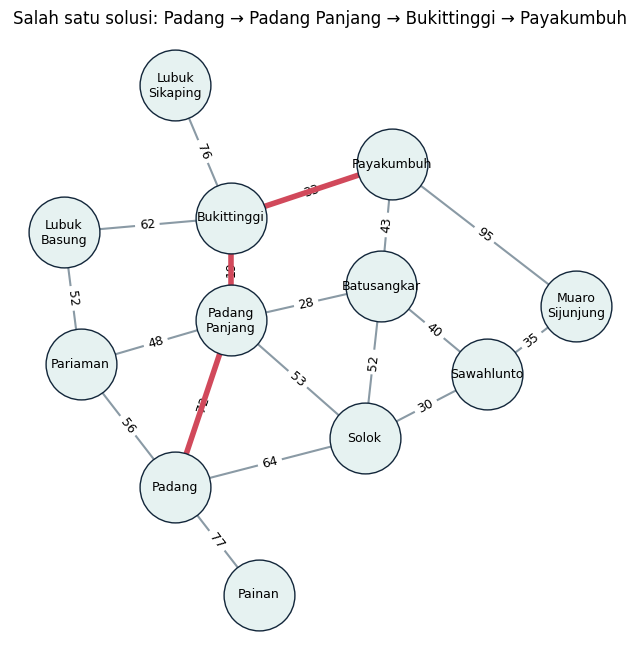

In [8]:
gambar_peta(G, jalur=["Padang", "Padang Panjang", "Bukittinggi", "Payakumbuh"],
            judul="Salah satu solusi: Padang → Padang Panjang → Bukittinggi → Payakumbuh")

## 3. Dari formulasi ke graf ruang keadaan

**Ruang keadaan** adalah himpunan semua status yang dapat dicapai dari status awal. Bila status digambar sebagai simpul dan aksi sebagai sisi berarah, kita memperoleh **graf ruang keadaan**.

Pada masalah rute, graf ruang keadaan kebetulan sama dengan peta. Pada masalah lain tidak ada peta: grafnya harus **dibangkitkan** dari `aksi` dan `hasil`. Fungsi berikut melakukannya untuk masalah apa pun.

In [9]:
from collections import deque

def bangun_ruang_keadaan(masalah, batas=100_000):
    """Menjelajah semua status yang terjangkau dari status awal, lalu mengembalikannya sebagai graf berarah."""
    R = nx.DiGraph()
    R.add_node(masalah.awal)
    antrean = deque([masalah.awal])
    while antrean and R.number_of_nodes() < batas:
        s = antrean.popleft()
        for a in masalah.aksi(s):
            s2 = masalah.hasil(s, a)
            if s2 not in R:
                R.add_node(s2)
                antrean.append(s2)
            R.add_edge(s, s2, aksi=str(a), biaya=masalah.biaya(s, a, s2))
    return R

R_rute = bangun_ruang_keadaan(rute)
print("Ruang keadaan masalah rute:", R_rute.number_of_nodes(), "status,", R_rute.number_of_edges(), "transisi")

Ruang keadaan masalah rute: 12 status, 36 transisi


### 3.1 Dunia penyedot debu (vacuum world)
Dua ruangan, A dan B. Status = (posisi robot, A kotor?, B kotor?). Aksi: `Kiri`, `Kanan`, `Sedot`. Tujuan: kedua ruangan bersih.

In [10]:
class DuniaPenyedot(Masalah):
    def __init__(self, awal=("A", True, True)):
        super().__init__(awal)
    def aksi(self, s):
        return ["Kiri", "Kanan", "Sedot"]
    def hasil(self, s, a):
        posisi, kotor_a, kotor_b = s
        if a == "Kiri":  return ("A", kotor_a, kotor_b)
        if a == "Kanan": return ("B", kotor_a, kotor_b)
        if posisi == "A": return ("A", False, kotor_b)      # Sedot di A
        return ("B", kotor_a, False)                         # Sedot di B
    def tujuan(self, s):
        return not s[1] and not s[2]

penyedot = DuniaPenyedot()
R_sedot = bangun_ruang_keadaan(penyedot)
print("Jumlah status:", R_sedot.number_of_nodes(), "(= 2 posisi × 2 × 2 kondisi kotor)")
for s in R_sedot.nodes:
    print(s, "← tujuan" if penyedot.tujuan(s) else "")

Jumlah status: 8 (= 2 posisi × 2 × 2 kondisi kotor)
('A', True, True) 
('B', True, True) 
('A', False, True) 
('B', True, False) 
('B', False, True) 
('A', True, False) 
('B', False, False) ← tujuan
('A', False, False) ← tujuan


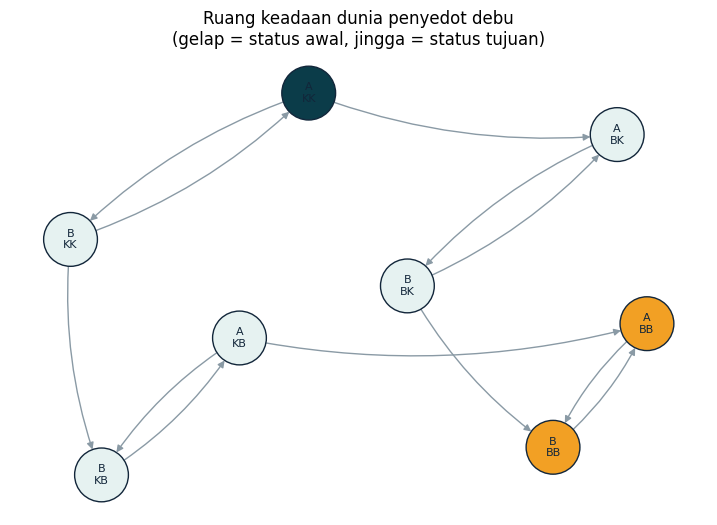

In [11]:
def gambar_ruang_keadaan(R, masalah, judul, ukuran=(9, 6), label=None, seed=3):
    pos = nx.spring_layout(R, seed=seed, k=1.3)
    warna = ["#F2A024" if masalah.tujuan(s) else ("#0B3C49" if s == masalah.awal else "#E6F2F1") for s in R]
    plt.figure(figsize=ukuran)
    nx.draw_networkx_nodes(R, pos, node_color=warna, node_size=1500, edgecolors="#12263A")
    nx.draw_networkx_labels(R, pos, labels={s: (label(s) if label else str(s)) for s in R}, font_size=8,
                            font_color="#12263A")
    sisi = [(u, v) for u, v in R.edges if u != v]
    nx.draw_networkx_edges(R, pos, edgelist=sisi, edge_color="#8A9AA5", arrows=True, node_size=1500,
                           connectionstyle="arc3,rad=0.12")
    plt.title(judul + "\n(gelap = status awal, jingga = status tujuan)"); plt.axis("off"); plt.show()

gambar_ruang_keadaan(R_sedot, penyedot, "Ruang keadaan dunia penyedot debu",
                     label=lambda s: f"{s[0]}\n{'K' if s[1] else 'B'}{'K' if s[2] else 'B'}")

### 3.2 Masalah ember air
Tersedia ember A (4 liter) dan ember B (3 liter), keduanya tanpa garis ukur, serta keran air. **Bagaimana memperoleh tepat 2 liter di ember A?**

- Status: pasangan `(isi A, isi B)`
- Aksi: isi penuh A, isi penuh B, buang A, buang B, tuang A→B, tuang B→A
- Biaya langkah: 1 per aksi

In [12]:
class EmberAir(Masalah):
    def __init__(self, kap_a=4, kap_b=3, target=2):
        super().__init__((0, 0))
        self.kap_a, self.kap_b, self.target = kap_a, kap_b, target
    def aksi(self, s):
        a, b = s
        pilihan = []
        if a < self.kap_a: pilihan.append("isi A")
        if b < self.kap_b: pilihan.append("isi B")
        if a > 0: pilihan.append("buang A")
        if b > 0: pilihan.append("buang B")
        if a > 0 and b < self.kap_b: pilihan.append("tuang A→B")
        if b > 0 and a < self.kap_a: pilihan.append("tuang B→A")
        return pilihan
    def hasil(self, s, aksi):
        a, b = s
        if aksi == "isi A":   return (self.kap_a, b)
        if aksi == "isi B":   return (a, self.kap_b)
        if aksi == "buang A": return (0, b)
        if aksi == "buang B": return (a, 0)
        if aksi == "tuang A→B":
            t = min(a, self.kap_b - b); return (a - t, b + t)
        if aksi == "tuang B→A":
            t = min(b, self.kap_a - a); return (a + t, b - t)
    def tujuan(self, s):
        return s[0] == self.target

ember = EmberAir()
R_ember = bangun_ruang_keadaan(ember)
print("Status yang mungkin secara teori :", (ember.kap_a + 1) * (ember.kap_b + 1))
print("Status yang benar-benar terjangkau:", R_ember.number_of_nodes())
print("Jumlah transisi                   :", R_ember.number_of_edges())
print("Status tujuan                     :", [s for s in R_ember if ember.tujuan(s)])

Status yang mungkin secara teori : 20
Status yang benar-benar terjangkau: 14
Jumlah transisi                   : 50
Status tujuan                     : [(2, 3), (2, 0)]


**Perhatikan:** dari 20 kombinasi `(a, b)` yang mungkin secara teori, tidak semuanya dapat dicapai. Ruang keadaan hanya memuat status yang **terjangkau** dari status awal.

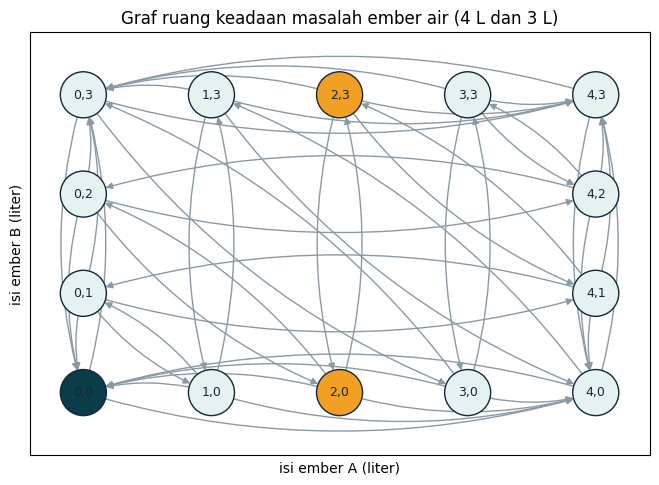

In [13]:
plt.figure(figsize=(8, 5.5))
pos = {s: s for s in R_ember}
warna = ["#F2A024" if ember.tujuan(s) else ("#0B3C49" if s == ember.awal else "#E6F2F1") for s in R_ember]
nx.draw_networkx_nodes(R_ember, pos, node_color=warna, node_size=1100, edgecolors="#12263A")
nx.draw_networkx_labels(R_ember, pos, font_size=9,
                        font_color="#12263A", labels={s: f"{s[0]},{s[1]}" for s in R_ember})
nx.draw_networkx_edges(R_ember, pos, edge_color="#8A9AA5", arrows=True, node_size=1100, connectionstyle="arc3,rad=0.15")
plt.xlabel("isi ember A (liter)"); plt.ylabel("isi ember B (liter)")
plt.title("Graf ruang keadaan masalah ember air (4 L dan 3 L)"); plt.show()

In [14]:
# Salah satu solusi (enam aksi). Minggu depan urutan seperti ini ditemukan otomatis oleh algoritma pencarian.
solusi_ember = ["isi A", "tuang A→B", "buang B", "tuang A→B", "isi A", "tuang A→B"]
akhir, biaya = jalankan(ember, solusi_ember)
print("Status akhir:", akhir, "| tujuan tercapai:", ember.tujuan(akhir), "| biaya:", biaya)

  (0, 0) --[isi A]--> (4, 0)   (akumulasi biaya 1)
  (4, 0) --[tuang A→B]--> (1, 3)   (akumulasi biaya 2)
  (1, 3) --[buang B]--> (1, 0)   (akumulasi biaya 3)
  (1, 0) --[tuang A→B]--> (0, 1)   (akumulasi biaya 4)
  (0, 1) --[isi A]--> (4, 1)   (akumulasi biaya 5)
  (4, 1) --[tuang A→B]--> (2, 3)   (akumulasi biaya 6)
Status akhir: (2, 3) | tujuan tercapai: True | biaya: 6


### 3.3 8-puzzle dan ledakan ruang keadaan
Papan 3×3 berisi kotak bernomor 1–8 dan satu kotak kosong. Aksi dipandang sebagai **menggeser kotak kosong** (bukan menggeser angka): cara pandang ini membuat jumlah aksi paling banyak 4.

Status direpresentasikan sebagai tuple 9 angka, dibaca per baris, dengan `0` sebagai kotak kosong.

In [15]:
class Puzzle8(Masalah):
    TUJUAN = (1, 2, 3, 4, 5, 6, 7, 8, 0)
    GESER = {"Atas": -3, "Bawah": 3, "Kiri": -1, "Kanan": 1}
    def __init__(self, awal):
        super().__init__(tuple(awal))
    def aksi(self, s):
        i = s.index(0); baris, kolom = divmod(i, 3)
        pilihan = []
        if baris > 0: pilihan.append("Atas")
        if baris < 2: pilihan.append("Bawah")
        if kolom > 0: pilihan.append("Kiri")
        if kolom < 2: pilihan.append("Kanan")
        return pilihan
    def hasil(self, s, a):
        i = s.index(0); j = i + self.GESER[a]
        papan = list(s); papan[i], papan[j] = papan[j], papan[i]
        return tuple(papan)
    def tujuan(self, s):
        return s == self.TUJUAN

def cetak_papan(s):
    for r in range(3):
        print(" ".join(str(x) if x else "·" for x in s[3*r:3*r+3]))

puzzle = Puzzle8((1, 2, 3, 4, 0, 6, 7, 5, 8))
cetak_papan(puzzle.awal)
print("\nAksi tersedia:", puzzle.aksi(puzzle.awal))
for a in puzzle.aksi(puzzle.awal):
    print(f"\nSetelah {a}:"); cetak_papan(puzzle.hasil(puzzle.awal, a))

1 2 3
4 · 6
7 5 8

Aksi tersedia: ['Atas', 'Bawah', 'Kiri', 'Kanan']

Setelah Atas:
1 · 3
4 2 6
7 5 8

Setelah Bawah:
1 2 3
4 5 6
7 · 8

Setelah Kiri:
1 2 3
· 4 6
7 5 8

Setelah Kanan:
1 2 3
4 6 ·
7 5 8


In [16]:
def status_per_kedalaman(masalah, kedalaman_maks):
    """Menghitung jumlah status BARU yang ditemukan pada setiap kedalaman."""
    dikunjungi = {masalah.awal}; lapis = [masalah.awal]; hasil = [1]
    for _ in range(kedalaman_maks):
        berikut = []
        for s in lapis:
            for a in masalah.aksi(s):
                s2 = masalah.hasil(s, a)
                if s2 not in dikunjungi:
                    dikunjungi.add(s2); berikut.append(s2)
        lapis = berikut; hasil.append(len(lapis))
    return hasil

per_lapis = status_per_kedalaman(Puzzle8(Puzzle8.TUJUAN), 31)
kumulatif = pd.Series(per_lapis).cumsum()
tabel = pd.DataFrame({"kedalaman": range(len(per_lapis)), "status baru": per_lapis, "kumulatif": kumulatif})
print(tabel.iloc[[0, 1, 2, 3, 5, 10, 15, 20, 25, 31]].to_string(index=False))
print("\nTotal status terjangkau:", int(kumulatif.iloc[-1]), "= 9!/2 =", 362880 // 2)

 kedalaman  status baru  kumulatif
         0            1          1
         1            2          3
         2            4          7
         3            8         15
         5           20         51
        10          286        706
        15         2512       7279
        20        16993      54802
        25        15578     155713
        31            2     181440

Total status terjangkau: 181440 = 9!/2 = 181440


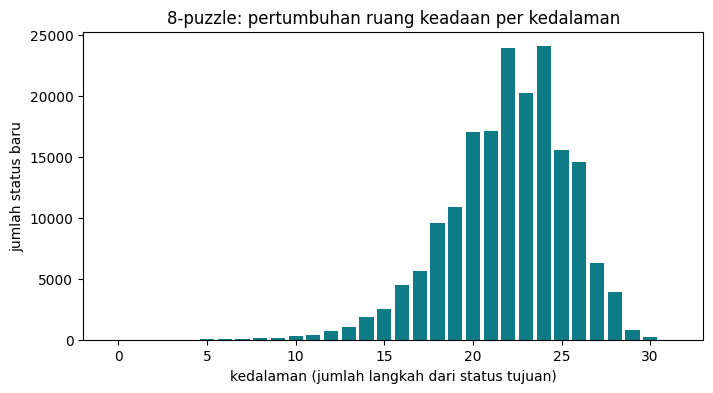

In [17]:
plt.figure(figsize=(8, 4))
plt.bar(range(len(per_lapis)), per_lapis, color="#0E7C86")
plt.xlabel("kedalaman (jumlah langkah dari status tujuan)"); plt.ylabel("jumlah status baru")
plt.title("8-puzzle: pertumbuhan ruang keadaan per kedalaman"); plt.show()

**Yang perlu dicatat:**
- 8-puzzle memiliki 9! = 362.880 susunan, tetapi hanya **separuhnya (181.440)** yang terjangkau dari satu status awal. Susunan lain tidak bisa diselesaikan.
- Susunan tersulit butuh 31 langkah.
- 15-puzzle (papan 4×4) memiliki sekitar 10¹³ status. Menambah satu baris dan satu kolom saja membuat ruang keadaan membengkak puluhan juta kali. Inilah **ledakan kombinatorial**, alasan kita butuh algoritma pencarian yang cerdas.

## 4. Abstraksi: memilih apa yang masuk ke dalam status

Formulasi yang baik membuang rincian yang tidak relevan. Pada masalah rute kita hanya menyimpan *nama kota*. Kondisi cuaca, isi bensin, dan lagu di radio tidak dimasukkan karena tidak mengubah keputusan pada tingkat perencanaan ini.

Tetapi abstraksi bergantung pada tujuan. Misalkan agen adalah **kurir yang harus mengantar paket ke Bukittinggi dan Solok** sebelum berakhir di Payakumbuh. Nama kota saja tidak cukup: status harus mencatat paket mana yang sudah diantar.

In [18]:
class MasalahKurir(Masalah):
    """Status = (kota saat ini, himpunan kota antar yang sudah dikunjungi)."""
    def __init__(self, graf, awal, wajib, akhir):
        super().__init__((awal, frozenset()))
        self.graf, self.wajib, self.akhir = graf, frozenset(wajib), akhir
    def aksi(self, s):
        return sorted(self.graf.neighbors(s[0]))
    def hasil(self, s, a):
        kota_sekarang, sudah = s
        if a in self.wajib:
            sudah = sudah | {a}
        return (a, sudah)
    def tujuan(self, s):
        return s[0] == self.akhir and s[1] == self.wajib
    def biaya(self, s, a, s2):
        return self.graf[s[0]][s2[0]]["jarak"]

kurir = MasalahKurir(G, "Padang", ["Bukittinggi", "Solok"], "Payakumbuh")
R_kurir = bangun_ruang_keadaan(kurir)
print("Masalah rute biasa :", R_rute.number_of_nodes(), "status")
print("Masalah kurir      :", R_kurir.number_of_nodes(), "status  (batas atas teoretis 12 kota × 4 catatan paket = 48)")

Masalah rute biasa : 12 status
Masalah kurir      : 42 status  (batas atas teoretis 12 kota × 4 catatan paket = 48)


Peta yang sama, tetapi ruang keadaannya **lebih dari tiga kali lebih besar** karena status kini memuat informasi tambahan. (Tidak genap 48 karena beberapa kombinasi mustahil, misalnya berada di Solok tetapi paket Solok belum tercatat.) Setiap informasi yang ditambahkan ke status melipatgandakan ukuran ruang keadaan. Karena itu: masukkan yang diperlukan, buang yang tidak.

---
## Latihan (bagian dari penilaian A1)

Kerjakan langsung pada sel yang disediakan. Jawaban uraian ditulis pada sel teks.

### Latihan 1 — Petani, serigala, kambing, dan kubis
Seorang petani harus menyeberangkan serigala, kambing, dan kubis dengan perahu yang hanya memuat petani ditambah **satu** bawaan. Bila ditinggal tanpa petani, serigala memakan kambing dan kambing memakan kubis.

Lengkapi kelas `Penyeberangan`:
- **Status**: tuple `(petani, serigala, kambing, kubis)`, masing-masing bernilai `"kiri"` atau `"kanan"`.
- **Aksi**: `"sendiri"`, `"serigala"`, `"kambing"`, `"kubis"` (apa yang dibawa petani menyeberang).
- Aksi yang menghasilkan status **berbahaya** tidak boleh ditawarkan oleh `aksi(s)`.

In [20]:

class Penyeberangan(Masalah):
    NAMA = ("petani", "serigala", "kambing", "kubis")

    def __init__(self):
        super().__init__(("kiri", "kiri", "kiri", "kiri"))

    def aman(self, s):
        petani, serigala, kambing, kubis = s

        # Serigala tidak boleh ditinggal bersama kambing
        if serigala == kambing and petani != serigala:
            return False

        # Kambing tidak boleh ditinggal bersama kubis
        if kambing == kubis and petani != kambing:
            return False

        return True

    def aksi(self, s):
        petani, serigala, kambing, kubis = s
        hasil_aksi = []

        # Petani bisa menyeberang sendirian atau membawa
        # satu objek yang berada di sisi yang sama
        for barang in (None, "serigala", "kambing", "kubis"):
            if barang is None:
                hasil_aksi.append(barang)
                continue

            posisi = s[self.NAMA.index(barang)]
            if posisi == petani:
                hasil_aksi.append(barang)

        # Simpan hanya aksi yang menghasilkan status aman
        sah = []
        for a in hasil_aksi:
            s2 = self.hasil(s, a)
            if self.aman(s2):
                sah.append(a)

        return sah

    def hasil(self, s, a):
        s2 = list(s)

        # Petani berpindah ke sisi seberang
        sisi_baru = "kanan" if s[0] == "kiri" else "kiri"
        s2[0] = sisi_baru

        # Jika membawa barang, barang ikut menyeberang
        if a is not None:
            indeks = self.NAMA.index(a)
            s2[indeks] = sisi_baru

        return tuple(s2)

    def tujuan(self, s):
        return all(posisi == "kanan" for posisi in s)


seberang = Penyeberangan()
R_seberang = bangun_ruang_keadaan(seberang)

print("Jumlah status terjangkau:", R_seberang.number_of_nodes())

if R_seberang.number_of_nodes() == 1:
    print("Kelas belum dilengkapi.")

Jumlah status terjangkau: 10


In [23]:

solusi_seberang = [
    "kambing",
    None,
    "serigala",
    "kambing",
    "kubis",
    None,
    "kambing"
]

if solusi_seberang:
    akhir, biaya = jalankan(seberang, solusi_seberang)
    print("Tujuan tercapai:", seberang.tujuan(akhir),
          "| jumlah penyeberangan:", biaya)

  ('kiri', 'kiri', 'kiri', 'kiri') --[kambing]--> ('kanan', 'kiri', 'kanan', 'kiri')   (akumulasi biaya 1)
  ('kanan', 'kiri', 'kanan', 'kiri') --[None]--> ('kiri', 'kiri', 'kanan', 'kiri')   (akumulasi biaya 2)
  ('kiri', 'kiri', 'kanan', 'kiri') --[serigala]--> ('kanan', 'kanan', 'kanan', 'kiri')   (akumulasi biaya 3)
  ('kanan', 'kanan', 'kanan', 'kiri') --[kambing]--> ('kiri', 'kanan', 'kiri', 'kiri')   (akumulasi biaya 4)
  ('kiri', 'kanan', 'kiri', 'kiri') --[kubis]--> ('kanan', 'kanan', 'kiri', 'kanan')   (akumulasi biaya 5)
  ('kanan', 'kanan', 'kiri', 'kanan') --[None]--> ('kiri', 'kanan', 'kiri', 'kanan')   (akumulasi biaya 6)
  ('kiri', 'kanan', 'kiri', 'kanan') --[kambing]--> ('kanan', 'kanan', 'kanan', 'kanan')   (akumulasi biaya 7)
Tujuan tercapai: True | jumlah penyeberangan: 7


### Latihan 2 — Mengubah tujuan mengubah ruang keadaan
Gunakan `EmberAir` dengan kapasitas lain, misalnya 5 liter dan 3 liter dengan target 4 liter.
1. Berapa status yang terjangkau? Berapa yang mungkin secara teori?
2. Temukan satu solusi dengan mencoba sendiri, lalu uji dengan `jalankan()`.
3. Adakah pasangan kapasitas dan target yang **tidak punya solusi**? Beri satu contoh dan buktikan dengan `bangun_ruang_keadaan`.

In [24]:
# Jawaban Latihan 2

# Ember berkapasitas 5 liter dan 3 liter, target 4 liter
ember = EmberAir(5, 3, 4)

R_ember = bangun_ruang_keadaan(ember)

print("Status terjangkau:", R_ember.number_of_nodes())
print("Status teoritis:", (5 + 1) * (3 + 1))

Status terjangkau: 16
Status teoritis: 24


1. Berapa status yang terjangkau? Berapa yang mungkin secara teori?

    Untuk ember berkapasitas 5 liter dan 3 liter dengan target 4 liter:

    Status yang mungkin secara teori adalah (5+1)×(3+1)=24 status.

    Status yang terjangkau adalah 16 status, berdasarkan operasi standar mengisi, mengosongkan, dan menuangkan air dari satu ember ke ember lainnya.

    

In [25]:

import pandas as pd
from IPython.display import display

tabel_solusi = pd.DataFrame({
    "Langkah": [0, 1, 2, 3, 4, 5, 6],
    "Aksi": [
        "Kondisi awal",
        "Isi ember 5 L",
        "Tuang ke ember 3 L",
        "Kosongkan ember 3 L",
        "Tuang ke ember 3 L",
        "Isi ember 5 L",
        "Tuang sampai ember 3 L penuh"
    ],
    "Ember 5 L": [0, 5, 2, 2, 0, 5, 4],
    "Ember 3 L": [0, 0, 3, 0, 2, 2, 3]
})

display(tabel_solusi)

,Langkah,Aksi,Ember 5 L,Ember 3 L
0,0,Kondisi awal,0,0
1,1,Isi ember 5 L,5,0
2,2,Tuang ke ember 3 L,2,3
3,3,Kosongkan ember 3 L,2,0
4,4,Tuang ke ember 3 L,0,2
5,5,Isi ember 5 L,5,2
6,6,Tuang sampai ember 3 L penuh,4,3


In [27]:
3. Adakah pasangan kapasitas dan target yang tidak punya solusi?

ember_gagal = EmberAir(4, 2, 3)
R_gagal = bangun_ruang_keadaan(ember_gagal)

print("Status terjangkau:", R_gagal.number_of_nodes())
print(
    "Target tercapai:",
    any(ember_gagal.tujuan(s) for s in R_gagal.nodes)
)

Object `solusi` not found.
Status terjangkau: 6
Target tercapai: False


### Latihan 3 — Formulasi kasus Anda sendiri
Pilih satu masalah dari keseharian kampus atau daerah asal Anda (contoh: rute antar gedung kampus, menyusun urutan antar pesanan, permainan tradisional sederhana). Tuliskan formulasinya pada tabel berikut, lalu implementasikan sebagai kelas turunan `Masalah` dan bangun graf ruang keadaannya.

| Komponen | Formulasi Anda |
|---|---|
| Representasi status | Lokasi yang dilewati selama perjalanan dari Koto Baru menuju Universitas Adzkia Padang. |
| Status awal | Rumah di Koto Baru, Padang. |
| Aksi | Memilih jalan atau melanjutkan perjalanan menuju kampus. |
| Model transisi | Berpindah dari lokasi saat ini ke lokasi berikutnya sesuai jalur perjalanan. |
| Uji tujuan | Bernilai benar jika sudah sampai di Universitas Adzkia Padang. |
| Biaya jalur | Waktu tempuh dalam menit dan jarak perjalanan dalam kilometer. |
| Perkiraan ukuran ruang keadaan | 3 status simulasi: Koto Baru, Jalan Menuju Kampus, dan Universitas Adzkia. |
| Rincian dunia nyata yang sengaja dibuang (abstraksi) | Kondisi cuaca, jenis kendaraan, lampu lalu lintas, dan perubahan kemacetan selama perjalanan. |

In [28]:
# Implementasi Latihan 3

class PerjalananAdzkia(Masalah):
    JALAN = {
        "Koto Baru": {
            "Jalan Menuju Kampus": (4, 15)
        },
        "Jalan Menuju Kampus": {
            "Koto Baru": (4, 15),
            "Universitas Adzkia": (3, 10)
        },
        "Universitas Adzkia": {
            "Jalan Menuju Kampus": (3, 10)
        }
    }

    def __init__(self):
        super().__init__("Koto Baru")

    def aksi(self, s):
        return list(self.JALAN[s].keys())

    def hasil(self, s, a):
        return a

    def tujuan(self, s):
        return s == "Universitas Adzkia"

    def biaya(self, s, a, s2):
        # Biaya jalur menggunakan waktu tempuh (menit)
        return self.JALAN[s][s2][1]


perjalanan = PerjalananAdzkia()
R_perjalanan = bangun_ruang_keadaan(perjalanan)

print("Jumlah status terjangkau:",
      R_perjalanan.number_of_nodes())
print("Jumlah hubungan jalan:",
      R_perjalanan.number_of_edges())

Jumlah status terjangkau: 3
Jumlah hubungan jalan: 4


3. Uji perjalanan ke kampus

In [29]:

solusi = [
    "Jalan Menuju Kampus",
    "Universitas Adzkia"
]

akhir, waktu = jalankan(perjalanan, solusi)

print("Lokasi awal: Koto Baru, Padang")
print("Lokasi akhir:", akhir)
print("Tujuan tercapai:", perjalanan.tujuan(akhir))
print("Jarak perjalanan: 7 km")
print("Waktu tempuh:", waktu, "menit")

  Koto Baru --[Jalan Menuju Kampus]--> Jalan Menuju Kampus   (akumulasi biaya 15)
  Jalan Menuju Kampus --[Universitas Adzkia]--> Universitas Adzkia   (akumulasi biaya 25)
Lokasi awal: Koto Baru, Padang
Lokasi akhir: Universitas Adzkia
Tujuan tercapai: True
Jarak perjalanan: 7 km
Waktu tempuh: 25 menit


### Refleksi
1. Mengapa formulasi masalah harus selesai sebelum memilih algoritma?

    Formulasi masalah harus selesai terlebih dahulu agar kita mengetahui status awal, tujuan, aksi, dan biaya yang harus diperhitungkan. Dengan begitu, kita bisa memilih algoritma yang sesuai untuk menyelesaikan masalah secara efektif.

2. Pada MasalahKurir, apa akibatnya bila status hanya berisi nama kota?

    Jika status hanya berisi nama kota, sistem tidak dapat membedakan kondisi penting lainnya, seperti barang yang sudah diantar atau pesanan yang belum selesai. Akibatnya, algoritma bisa menghasilkan solusi yang tidak sesuai dengan kondisi sebenarnya.

3. Sebutkan satu keputusan abstraksi pada Latihan 3 yang dapat berdampak buruk bagi pengguna bila sistemnya benar-benar dipakai.

    Pada Latihan 3, perubahan kondisi kemacetan selama perjalanan diabaikan. Jika sistem benar-benar digunakan, pengguna bisa diarahkan ke jalan yang ternyata macet sehingga waktu perjalanan menjadi lebih lama dari perkiraan.

---
**Pengumpulan:** *File → Download → Download .ipynb*, beri nama `P03_NIM_Nama.ipynb`, unggah ke LMS bersama lembar tugas analisis kasus.